# Solutions to notebook 11: Nonlinear waves: solitons, shocks and chaos

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/11_nonlinear_waves.ipynb)

Worked solutions to the exercises at the end of [notebook 11](../notebooks/11_nonlinear_waves.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import rfft, irfft, fft, ifft

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# functions from notebook 11
def wavenumbers(N, L):
    """Wavenumbers k = 2πn/L, n = 0..N/2, of real data with period L on N points (for rfft)."""
    return 2 * np.pi * np.fft.rfftfreq(N, d=L / N)

def advection_term(k):
    """Function that maps the rfft of u to the rfft of -u u_x = -(u²/2)_x."""
    N = 2 * (len(k) - 1)
    ik = 1j * k
    ik[-1] = 0                                             # Nyquist mode: no odd derivative
    return lambda u_hat: -0.5 * ik * rfft(irfft(u_hat, N) ** 2)

def ifrk4(u_hat, symbol, nonlinear, dt, steps):
    """Advance u_hat' = symbol * u_hat + nonlinear(u_hat) by `steps` steps of integrating-factor RK4."""
    E = np.exp(symbol * dt / 2)
    E2 = E * E
    for _ in range(steps):
        a = dt * nonlinear(u_hat)
        b = dt * nonlinear(E * (u_hat + a / 2))
        c = dt * nonlinear(E * u_hat + b / 2)
        d = dt * nonlinear(E2 * u_hat + E * c)
        u_hat = E2 * u_hat + (E2 * a + 2 * E * (b + c) + d) / 6
    return u_hat

def soliton(x, t, c, x0, L=30.0):
    """KdV solitary wave of speed c that starts at x0, wrapped onto the periodic domain of length L."""
    distance = (x - c * t - x0 + L / 2) % L - L / 2
    return 3 * c / np.cosh(np.sqrt(c) / 2 * distance) ** 2

# fourier_interpolate(v, M) from notebook 2
def fourier_interpolate(v, M):
    """Values of the trigonometric interpolant of v (N samples, N even) on the periodic grid of M > N points."""
    N = len(v)
    v_hat = np.fft.fft(v)
    padded = np.zeros(M, dtype=complex)
    padded[: N // 2] = v_hat[: N // 2]                         # k = 0, ..., N/2 - 1
    padded[M - N // 2 + 1 :] = v_hat[N // 2 + 1 :]             # k = -N/2 + 1, ..., -1
    padded[N // 2] = padded[M - N // 2] = v_hat[N // 2] / 2    # the Nyquist mode, shared between ±N/2
    return np.real(np.fft.ifft(padded)) * M / N

def peaks(u, L, refine=16):
    """Positions and heights of the local maxima of periodic data, highest first."""
    M = refine * len(u)
    fine = fourier_interpolate(u, M)                        # the trigonometric interpolant on M points
    xf = -L / 2 + L * np.arange(M) / M
    j = np.flatnonzero((fine > np.roll(fine, 1)) & (fine >= np.roll(fine, -1)) & (fine > 0.1 * fine.max()))
    left, mid, right = fine[j - 1], fine[j], fine[(j + 1) % M]
    shift = 0.5 * (left - right) / (left - 2 * mid + right)  # vertex of the parabola, in grid units
    order = np.argsort(-mid)
    return (xf[j] + shift * L / M)[order], (mid - 0.25 * (left - right) * shift)[order]

def burgers(N, nu, t_end, dt):
    """Pseudo-spectral Burgers solution from u = sin x: integrating factor for the viscous term."""
    x = 2 * np.pi * np.arange(N) / N
    k = wavenumbers(N, 2 * np.pi)
    u_hat = ifrk4(rfft(np.sin(x)), -nu * k**2, advection_term(k), dt, round(t_end / dt))
    return x, irfft(u_hat, N)

def cole_hopf_kernel(x, t, nu, n=4001):
    """Exact Burgers solution for u(x, 0) = sin x from the heat-kernel form; safe for small ν."""
    s = np.linspace(-3 * np.pi, 3 * np.pi, n)
    exponent = -s**2 / (4 * nu * t) + np.cos(x[:, None] - s) / (2 * nu)
    w = np.exp(exponent - exponent.max(axis=1, keepdims=True))        # scaled to avoid overflow
    return (w * s).sum(axis=1) / w.sum(axis=1) / t

def tail(u):
    """Largest of the last four Fourier amplitudes: the part of the spectrum the grid barely holds."""
    return (2 * np.abs(rfft(u)) / len(u))[-4:].max()

def phi_functions(z, points=32):
    """φ1, φ2, φ3 at the entries of z, as means over circles of radius 1 (no cancellation)."""
    circle = np.exp(2j * np.pi * (np.arange(points) + 0.5) / points)
    zc = np.asarray(z)[..., None] + circle
    ez = np.exp(zc)
    phi = (ez - 1) / zc, (ez - 1 - zc) / zc**2, (ez - 1 - zc - zc**2 / 2) / zc**3
    return [p.mean(axis=-1) for p in phi]

def etdrk4_setup(symbol, dt):
    """Coefficients of the ETDRK4 scheme for u_hat' = symbol * u_hat + nonlinear(u_hat)."""
    p1, p2, p3 = phi_functions(symbol * dt)
    coefficients = [np.exp(symbol * dt), np.exp(symbol * dt / 2), dt / 2 * phi_functions(symbol * dt / 2)[0],
                    dt * (p1 - 3 * p2 + 4 * p3), dt * (2 * p2 - 4 * p3), dt * (4 * p3 - p2)]
    if np.isrealobj(symbol):                                # real symbol: the imaginary parts are rounding errors
        coefficients = [np.real(c) for c in coefficients]
    return coefficients

def etdrk4_step(u_hat, coefficients, nonlinear):
    """One ETDRK4 step: two half-step stages, one full-step stage, then the weighted sum."""
    E, E_half, Q, w1, w23, w4 = coefficients
    n1 = nonlinear(u_hat)
    a = E_half * u_hat + Q * n1
    n2 = nonlinear(a)
    b = E_half * u_hat + Q * n2
    n3 = nonlinear(b)
    c = E_half * a + Q * (2 * n3 - n1)
    n4 = nonlinear(c)
    return E * u_hat + w1 * n1 + w23 * (n2 + n3) + w4 * n4

In [3]:
# a helper for exercises 1 and 2: the KdV time loop of 11.4 as a function
def kdv_history(u0, L, dt, steps_per_frame, frames):
    """Solve the KdV equation from u0 on a domain of period L. Returns the stored profiles and their times."""
    N = len(u0)
    k = wavenumbers(N, L)
    kdv_symbol = 1j * k**3
    kdv_symbol[-1] = 0                                     # odd derivative: drop the Nyquist mode
    kdv_nonlinear = advection_term(k)
    u_hat = rfft(u0)
    history = [u0]
    for _ in range(frames):
        u_hat = ifrk4(u_hat, kdv_symbol, kdv_nonlinear, dt, steps_per_frame)
        history.append(irfft(u_hat, N))
    return np.array(history), dt * steps_per_frame * np.arange(frames + 1)

## Exercise 1

**Soliton fission.** Solve the KdV equation of 11.3 on the same grid ($N = 256$, $L = 30$)
from the initial condition $u(x, 0) = 36\,\operatorname{sech}^2(x + 8)$, which is *not* a
single soliton (a soliton of height 36 would have $\operatorname{sech}^2(\sqrt3\,(x+8))$).
Run to $t = 1$ with $\Delta t = 10^{-4}$ and use `peaks` to find how many solitons emerge
and their heights. Theory predicts exactly two, of heights 48 and 12. Check also that each
travels at one third of its height.

The hump is wider than a soliton of its height, so it holds more mass than one soliton can
carry and must split. Store 100 profiles, read the peaks from the last one, and get the speeds
from a straight-line fit to the peak positions over the last 0.2 time units, when the two waves
are well apart. A soliton $3c\,\operatorname{sech}^2(\sqrt c\,x/2)$ has mass $12\sqrt c$ and
momentum $24c^{3/2}$, so the two predicted solitons can also be checked against the invariants
of the initial hump.

number of peaks at t = 1: 2
heights   48.00000 and 12.00000    theory 48 and 12
speeds    16.00000 and 4.00000    height/3 = 16.00000 and 4.00000
positions +8.27465 and -4.54931
mass 71.9999 (two solitons: 72),  momentum 1728.000 (two solitons: 1728)


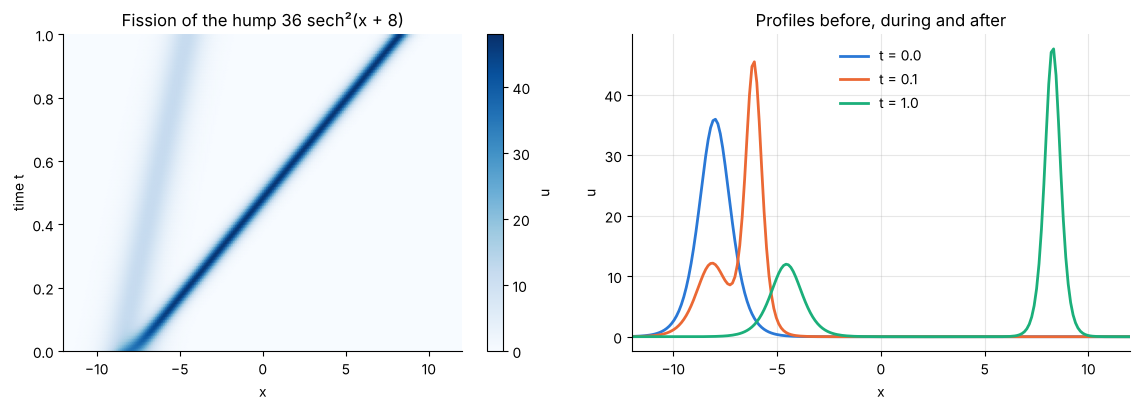

In [4]:
N, L = 256, 30.0
x = -L / 2 + L * np.arange(N) / N
u0 = 36 / np.cosh(x + 8) ** 2
history, times = kdv_history(u0, L, 1e-4, 100, 100)

positions, heights = peaks(history[-1], L)
late = times >= 0.8
tracks = np.array([peaks(u, L)[0] for u in history[late]])
speeds = np.polyfit(times[late], tracks, 1)[0]
h = L / N
mass, momentum = history[-1].sum() * h, (history[-1] ** 2).sum() * h
print(f"number of peaks at t = 1: {len(positions)}")
print(f"heights   {heights[0]:.5f} and {heights[1]:.5f}    theory 48 and 12")
print(f"speeds    {speeds[0]:.5f} and {speeds[1]:.5f}    height/3 = {heights[0] / 3:.5f} and {heights[1] / 3:.5f}")
print(f"positions {positions[0]:+.5f} and {positions[1]:+.5f}")
print(f"mass {mass:.4f} (two solitons: {12 * (4 + 2)}),  momentum {momentum:.3f} (two solitons: {24 * (64 + 8)})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
mesh = ax1.pcolormesh(x, times, history, cmap="Blues", shading="gouraud", rasterized=True)
ax1.set(xlim=(-12, 12), xlabel="x", ylabel="time t", title="Fission of the hump 36 sech²(x + 8)")
ax1.grid(False)
fig.colorbar(mesh, ax=ax1, label="u")
for frame in (0, 10, 100):
    ax2.plot(x, history[frame], label=f"t = {times[frame]:.1f}")
ax2.set(xlim=(-12, 12), xlabel="x", ylabel="u", title="Profiles before, during and after")
ax2.legend(frameon=False, loc="upper center")
fig.tight_layout()

In [5]:
# verify: the heights and speeds predicted by soliton theory, the invariants of two exact solitons,
# and the positions given by the exact two-soliton solution (see the answer)
assert len(positions) == 2 and np.allclose(heights, [48, 12], rtol=1e-5)
assert np.allclose(speeds, heights / 3, rtol=1e-5)
assert abs(mass - 72) < 1e-3 and abs(momentum - 1728) < 1e-3
assert abs(history[-1].sum() - u0.sum()) * h < 1e-10
assert np.allclose(positions, [-8 + 16 + np.log(3) / 4, -8 + 4 - np.log(3) / 2], atol=1e-5)

**Answer.** Exactly two solitons emerge, of heights 48.00000 and 12.00000, travelling at
16.00000 and 4.00000, one third of their heights. Their masses, $48 + 24 = 72$, and momenta,
$1536 + 192 = 1728$, add up to those of the initial hump, so nothing is left over as ripples.
The hump $36\,\operatorname{sech}^2(x + 8)$ is in fact the exact two-soliton solution of 11.4
caught at the instant when the tall soliton sits on top of the short one. That explains the
final positions: $+8.27465$ and $-4.54931$ are $-8 + ct$ plus $\tfrac14\ln 3$ and minus
$\tfrac12\ln 3$, half of the phase shifts of a complete collision. For an engineer the lesson
is that a long swell entering shallow water does not keep its shape: it breaks up into a train
of solitary waves ordered by height, the tallest in front.

## Exercise 2

**Phase shifts for other speeds.** Repeat the collision of 11.4 with $c_1 = 9$ and $c_2 = 1$
on a domain of length $L = 60$ with $N = 512$, starting the solitons at $x_1 = -20$ and
$x_2 = -8$ and running to $t = 4$ with $\Delta t = 2\times10^{-4}$. Measure both phase shifts
and compare them with the formula of 11.4.

Now $\kappa_1 = \tfrac32$ and $\kappa_2 = \tfrac12$, so
$\ln\big((\kappa_1 + \kappa_2)/(\kappa_1 - \kappa_2)\big) = \ln 2$ and the predicted shifts are
$+\tfrac23\ln 2 = +0.4621$ for the tall soliton and $-2\ln 2 = -1.3863$ for the short one.
The slow soliton is wide (width $2/\sqrt{c_2} = 2$), which is why the domain is longer.
The measured shift is the final peak position minus the position $x_i + c_iT$ the soliton would
have reached alone.

heights at t = 4: 27.0002 and 3.0000    (before: 27 and 3)
phase shift of the tall soliton  +0.4623   theory +0.4621
phase shift of the short soliton -1.3863   theory -1.3863


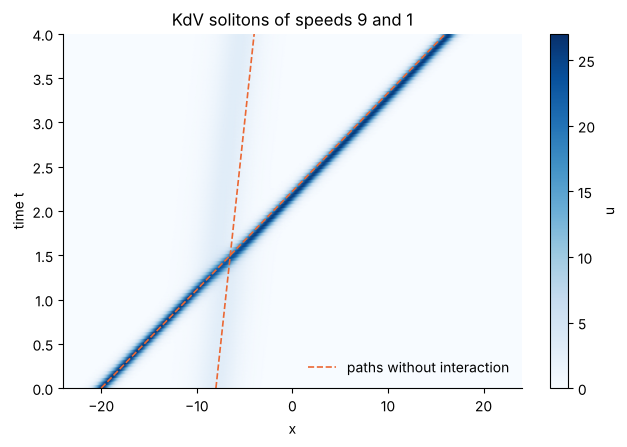

In [6]:
N, L = 512, 60.0
x = -L / 2 + L * np.arange(N) / N
c1, x1, c2, x2 = 9.0, -20.0, 1.0, -8.0
u0 = soliton(x, 0, c1, x1, L) + soliton(x, 0, c2, x2, L)             # L = 60 here, not the default 30
history, times = kdv_history(u0, L, 2e-4, 200, 100)
T = times[-1]

positions, heights = peaks(history[-1], L)
shift_tall, shift_short = positions[0] - (x1 + c1 * T), positions[1] - (x2 + c2 * T)
kappa1, kappa2 = np.sqrt(c1) / 2, np.sqrt(c2) / 2
log_term = np.log((kappa1 + kappa2) / (kappa1 - kappa2))
print(f"heights at t = {T:.0f}: {heights[0]:.4f} and {heights[1]:.4f}    (before: 27 and 3)")
print(f"phase shift of the tall soliton  {shift_tall:+.4f}   theory {log_term / kappa1:+.4f}")
print(f"phase shift of the short soliton {shift_short:+.4f}   theory {-log_term / kappa2:+.4f}")

fig, ax = plt.subplots(figsize=(7.4, 4.6))
mesh = ax.pcolormesh(x, times, history, cmap="Blues", shading="gouraud", rasterized=True)
for c, x0, label in ((c1, x1, "paths without interaction"), (c2, x2, None)):
    ax.plot(x0 + c * times, times, "--", color="#eb6834", lw=1.2, label=label)
ax.set(xlim=(-24, 24), ylim=(0, T), xlabel="x", ylabel="time t", title="KdV solitons of speeds 9 and 1")
ax.grid(False)
ax.legend(frameon=False, loc="lower right")
fig.colorbar(mesh, label="u");

In [7]:
# verify: the phase shifts of the exact two-soliton solution, unchanged heights, and conservation of mass
assert len(positions) == 2 and np.allclose(heights, [3 * c1, 3 * c2], rtol=1e-4)
assert abs(shift_tall - log_term / kappa1) < 1e-3 and abs(shift_short + log_term / kappa2) < 1e-3
assert abs(history[-1].sum() - u0.sum()) * L / N < 1e-10

**Answer.** The tall soliton comes out $+0.4623$ ahead (theory $+0.4621$) and the short one
$-1.3863$ behind (theory $-1.3863$), with heights 27.0002 and 3.0000. The small excess of the
tall soliton, in height and in shift, comes from the initial condition and not from the
solver: at $t = 0$ the tail of the wide short soliton adds about $10^{-4}$ to the tall one,
which therefore runs a little faster than $c_1 = 9$. Compared with 11.4 the speed ratio is
larger (9 against 4) and the shifts are smaller in units of each soliton's width: the more the
speeds differ, the briefer the encounter and the weaker its trace.

## Exercise 3

**A soliton of the nonlinear Schrödinger equation.** The equation
$i\psi_t + \tfrac12\psi_{xx} + |\psi|^2\psi = 0$ for a complex field $\psi$ has the solution
$\psi = a\,\operatorname{sech}\!\big(a(x - Vt)\big)\exp\!\big(i\,[Vx + \tfrac12(a^2 - V^2)t]\big)$.
Write an integrating-factor RK4 code for it (the data are complex, so use `fft`, `ifft` and
`np.fft.fftfreq`; the symbol is $-ik^2/2$ and the nonlinear term is $i|\psi|^2\psi$). With
$a = 2$, $V = 1$, $L = 40$, $N = 256$ and $\Delta t = 10^{-3}$, verify the solution at
$t = 4$ to $10^{-6}$ and check that $\int|\psi|^2dx = 2a$ is conserved.

Solve for the time derivative: $\psi_t = \tfrac{i}{2}\psi_{xx} + i|\psi|^2\psi$. The linear term
has the symbol $\tfrac{i}{2}(ik)^2 = -ik^2/2$, and `ifrk4` works unchanged because it only
multiplies arrays. The second derivative is even, so the Nyquist mode is kept. The factor
$e^{iVx}$ is not periodic on this domain, but that does no harm: at the ends
$|\psi| = 2\operatorname{sech}(40) \approx 10^{-17}$.

N = 256: largest error at t = 4: 1.5e-07        (N = 512, same time step: 1.2e-09)
integral of |ψ|²: 4.000000000010 at t = 0, 4.000000000010 at t = 4, exact 2a = 4.0


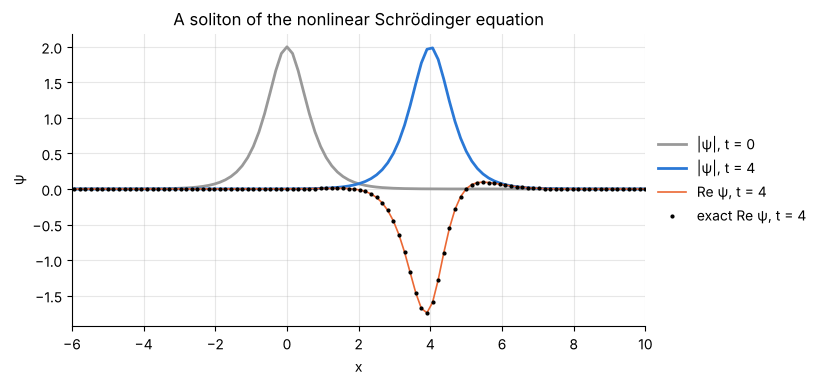

In [8]:
a, V, L, dt = 2.0, 1.0, 40.0, 1e-3

def nls_soliton(x, t):
    """Exact soliton of the nonlinear Schrödinger equation with amplitude a and speed V."""
    return a / np.cosh(a * (x - V * t)) * np.exp(1j * (V * x + 0.5 * (a**2 - V**2) * t))

def nls_nonlinear(psi_hat):
    """Maps the fft of ψ to the fft of i |ψ|² ψ."""
    psi = ifft(psi_hat)
    return fft(1j * np.abs(psi) ** 2 * psi)

def nls_solve(N, t_end):
    x = -L / 2 + L * np.arange(N) / N
    k = 2 * np.pi * np.fft.fftfreq(N, d=L / N)
    return x, ifft(ifrk4(fft(nls_soliton(x, 0)), -0.5j * k**2, nls_nonlinear, dt, round(t_end / dt)))

x, psi = nls_solve(256, 4.0)
error = np.abs(psi - nls_soliton(x, 4.0)).max()
norm_start, norm_end = (np.abs(nls_soliton(x, 0)) ** 2).sum() * L / 256, (np.abs(psi) ** 2).sum() * L / 256
x_fine, psi_fine = nls_solve(512, 4.0)
error_fine = np.abs(psi_fine - nls_soliton(x_fine, 4.0)).max()
print(f"N = 256: largest error at t = 4: {error:.1e}        (N = 512, same time step: {error_fine:.1e})")
print(f"integral of |ψ|²: {norm_start:.12f} at t = 0, {norm_end:.12f} at t = 4, exact 2a = {2 * a}")

fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.plot(x, np.abs(nls_soliton(x, 0)), color="0.6", label="|ψ|, t = 0")
ax.plot(x, np.abs(psi), label="|ψ|, t = 4")
ax.plot(x, psi.real, lw=1.2, label="Re ψ, t = 4")
ax.plot(x, nls_soliton(x, 4.0).real, "k.", ms=4, label="exact Re ψ, t = 4")
ax.set(xlim=(-6, 10), xlabel="x", ylabel="ψ", title="A soliton of the nonlinear Schrödinger equation")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [9]:
# verify: the exact soliton at t = 4, and the conserved integral against its exact value 2a
assert error < 1e-6
assert abs(norm_end - 2 * a) < 1e-9 and abs(norm_end - norm_start) < 1e-9
assert error_fine < error / 50                            # the error at N = 256 is spatial, not from the time step

**Answer.** At $t = 4$ the soliton has moved 4 units and the largest error is
$1.5\times10^{-7}$, within the $10^{-6}$ asked for; $\int|\psi|^2dx = 4.000000000$ at both
times. The error at $N = 256$ is the spatial resolution of this narrow pulse: with $N = 512$
and the same time step it falls to $1.2\times10^{-9}$, which is the error of the time
stepping. The envelope $|\psi|$ travels unchanged
while the phase under it rotates, which is how a pulse of light keeps its shape along an
optical fibre.

## Exercise 4

**Shock thickness.** For the Burgers problem of 11.5 at $t = 2$, compute the steepest slope
$\max|u_x|$ for $\nu = 0.1$, 0.05 and 0.025, each with a grid fine enough that the spectrum
tail is below $10^{-10}$ (state the $N$ you needed). Compare each with the steady-shock
estimate $U^2/(2\nu)$, where $U$ is the largest value of $u$ at that time. Show that the
ratio of successive slopes approaches 2 as $\nu$ is halved, and that the estimate improves
as $\nu$ falls.

Double $N$ until `tail` is below $10^{-10}$, with $\Delta t = 0.4/N$ so that the time step
shrinks with the grid. The slope comes from the Fourier derivative, and $U$ from the
trigonometric interpolant on a grid 16 times finer, since the largest value of $u$ falls
between grid points.

For an independent check, differentiate the heat-kernel formula of 11.5 with respect to $x$.
With $g = -\sin(x - s)/(2\nu)$, the derivative of the exponent of $w$, and
$\langle\cdot\rangle$ the average over $s$ with weight $w$,

$$u_x = \frac{\langle s\,g\rangle - \langle s\rangle\langle g\rangle}{t} .$$

By symmetry the front stays at $x = \pi$, so the formula is evaluated there.

   ν       N    tail      max|u_x|      U       U²/(2ν)   slope/estimate   error in u   error in slope


 0.100    128  7.7e-11     3.51537   0.75509     2.8508       1.2331       2.5e-10      3.7e-09


 0.050    256  9.3e-11     7.96395   0.84485     7.1377       1.1158       5.2e-10      1.3e-08


 0.025    512  9.3e-11    17.03669   0.89370    15.9741       1.0665       8.2e-10      4.0e-08
growth of the slope for each halving of ν: [2.2655 2.1392]


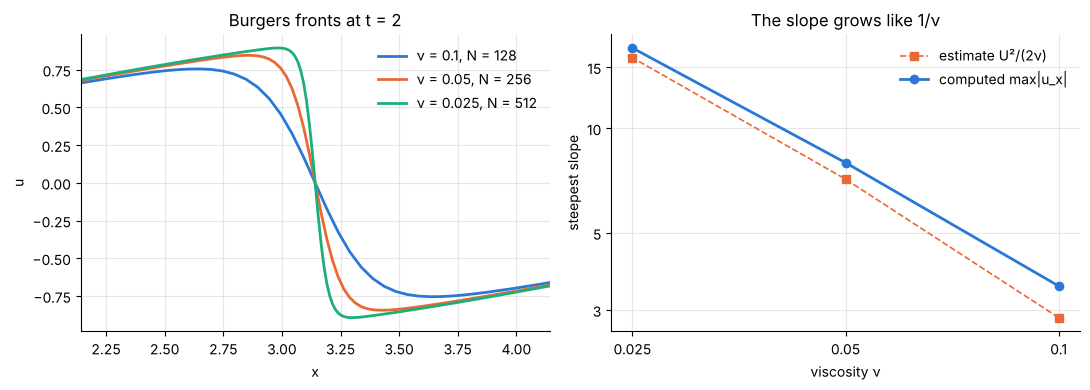

In [10]:
def exact_slope_at_front(t, nu, n=8001):
    """u_x at x = π for the Burgers solution from u = sin x, from the heat-kernel form."""
    s = np.linspace(-3 * np.pi, 3 * np.pi, n)
    exponent = -s**2 / (4 * nu * t) + np.cos(np.pi - s) / (2 * nu)
    w = np.exp(exponent - exponent.max())
    w /= w.sum()
    g = -np.sin(np.pi - s) / (2 * nu)
    return ((w * s * g).sum() - (w * s).sum() * (w * g).sum()) / t

results = {}
print("   ν       N    tail      max|u_x|      U       U²/(2ν)   slope/estimate   error in u   error in slope")
for nu in (0.1, 0.05, 0.025):
    N = 32
    while True:
        N *= 2
        x, u = burgers(N, nu, 2.0, 0.4 / N)
        if tail(u) < 1e-10:
            break
    ik = 1j * wavenumbers(N, 2 * np.pi)
    ik[-1] = 0
    slope = np.abs(irfft(ik * rfft(u), N)).max()
    U = fourier_interpolate(u, 16 * N).max()
    error_u = np.abs(u - cole_hopf_kernel(x, 2.0, nu)).max()
    error_slope = abs(slope + exact_slope_at_front(2.0, nu))
    results[nu] = N, slope, U, error_u, error_slope, x, u
    print(f"{nu:6.3f}  {N:5d}  {tail(u):.1e}   {slope:9.5f}   {U:.5f}   {U**2 / (2 * nu):8.4f}   {slope / (U**2 / (2 * nu)):10.4f}"
          f"       {error_u:.1e}      {error_slope:.1e}")

slopes = np.array([r[1] for r in results.values()])
estimates = np.array([r[2] ** 2 / (2 * nu) for nu, r in results.items()])
print("growth of the slope for each halving of ν:", np.round(slopes[1:] / slopes[:-1], 4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for nu, (N, slope, U, _, _, x, u) in results.items():
    ax1.plot(x, u, label=f"ν = {nu}, N = {N}")
ax1.set(xlim=(np.pi - 1, np.pi + 1), xlabel="x", ylabel="u", title="Burgers fronts at t = 2")
ax1.legend(frameon=False, loc="upper right")
ax2.loglog(list(results), estimates, "s--", ms=6, lw=1.2, color="#eb6834", label="estimate U²/(2ν)")
ax2.loglog(list(results), slopes, "o-", ms=6, label="computed max|u_x|")
ax2.set(xlabel="viscosity ν", ylabel="steepest slope", title="The slope grows like 1/ν")
ax2.minorticks_off()
ax2.set_xticks([0.025, 0.05, 0.1], labels=["0.025", "0.05", "0.1"])
ax2.set_yticks([3, 5, 10, 15], labels=["3", "5", "10", "15"])
ax2.legend(frameon=False, loc="upper right")
fig.tight_layout()

In [11]:
# verify: the solution and its slope against the exact Cole-Hopf solution in heat-kernel form,
# and the trend of the two ratios towards their limits 2 and 1
for nu, (N, slope, U, error_u, error_slope, x, u) in results.items():
    assert error_u < 1e-8 and error_slope < 1e-6 * slope
assert [r[0] for r in results.values()] == [128, 256, 512]
growth = slopes[1:] / slopes[:-1]
excess = slopes / estimates
assert np.all((growth > 2) & (growth < 2.3)) and growth[1] < growth[0]
assert np.all(np.diff(excess) < 0) and 1 < excess[-1] < 1.1

**Answer.**

| $\nu$ | $N$ needed | $\max\lvert u_x\rvert$ | $U$ | $U^2/(2\nu)$ | ratio |
| --- | --- | --- | --- | --- | --- |
| 0.1 | 128 | 3.5154 | 0.7551 | 2.851 | 1.233 |
| 0.05 | 256 | 7.9640 | 0.8448 | 7.138 | 1.116 |
| 0.025 | 512 | 17.0367 | 0.8937 | 15.974 | 1.067 |

The ratio of successive slopes is 2.27 and then 2.14 as $\nu$ is halved: it approaches 2 from
above. It is more than 2 because a less viscous wave has also decayed less by $t = 2$, so $U$
is larger. The computed slope is 23, 12 and 7 per cent above the steady-shock estimate, so the
estimate improves as $\nu$ falls. It is low because it takes $U$ from the rounded top of the
profile, which lies below the level the front would connect to without viscosity, and the gap
closes as $\nu$ falls. The grid needed doubles with each halving of $\nu$,
$N \approx 13/\nu$ for ten digits, as 11.5 predicted.

## Exercise 5

**The onset of the Kuramoto-Sivashinsky instability.** On a domain of length $L$ the
longest wave has $k = 2\pi/L$, so the flat state $u = 0$ is stable when $L < 2\pi$. With
$N = 64$, $\Delta t = 0.1$ and the initial condition $u = 0.01\cos(2\pi x/L)$, run the KS
code to $t = 100$ for $L = 6$ and for $L = 10$. For $L = 6$, measure the decay rate of the
amplitude and compare it with $k^2 - k^4$. For $L = 10$, show that the solution settles to a
steady cellular state, and report its largest value of $|u|$ at $t = 100$ and how much that
value changes between $t = 90$ and $t = 100$.

Wrap the ETDRK4 loop of 11.6 in a function of $L$ that stores every step. For $L = 6$ the
amplitude is that of the one mode present, $2|\hat u_1|/N$, and its decay rate is the slope of
a straight-line fit to its logarithm; fitting over $t \ge 50$ avoids the early times when the
nonlinear term still has a small effect. For $L = 10$, a steady state must make the right-hand
side of the equation vanish, which can be tested directly without reference to the time
stepping.

L = 6:  k = 1.0472, measured decay rate -0.10595866, k² - k⁴ = -0.10595866, amplitude at t = 100: 2.50e-07


L = 10: k = 0.6283, early growth rate 0.2382, k² - k⁴ = 0.2389
        largest |u| at t = 100: 1.9612 from the interpolant; at the grid points 1.9608728869, change since t = 90: 0.0e+00
        largest |u_t| at t = 100: 2.3e-11;  with N = 128, dt = 0.05 the largest |u| is 1.9608728869
        amplitudes of modes 1 to 4: [1.5605 0.7085 0.1122 0.0158]


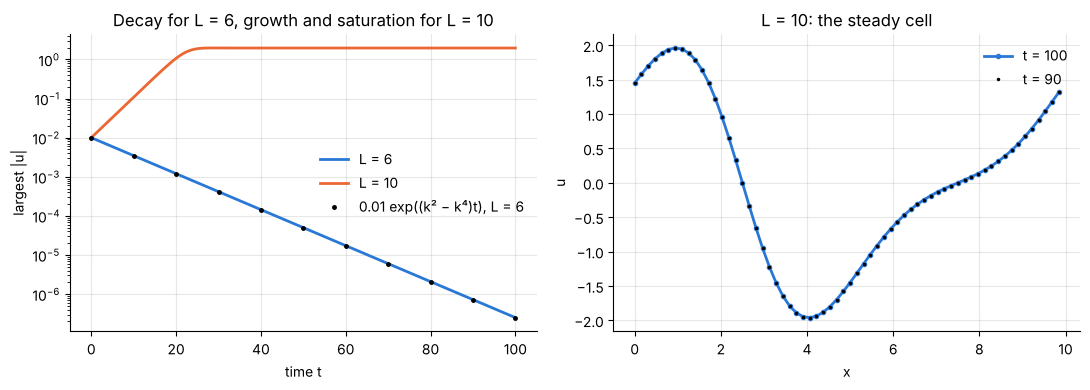

In [12]:
def ks_history(L, N=64, dt=0.1, t_end=100.0):
    """KS solution from u = 0.01 cos(2πx/L) on a domain of period L. Returns x, k, the times and all profiles."""
    x = L * np.arange(N) / N
    k = wavenumbers(N, L)
    coefficients, nonlinear = etdrk4_setup(k**2 - k**4, dt), advection_term(k)
    u_hat = rfft(0.01 * np.cos(2 * np.pi * x / L))
    history = [irfft(u_hat, N)]
    for _ in range(round(t_end / dt)):
        u_hat = etdrk4_step(u_hat, coefficients, nonlinear)
        history.append(irfft(u_hat, N))
    return x, k, dt * np.arange(len(history)), np.array(history)

# L = 6: the flat state is stable
x6, k6, times, history6 = ks_history(6.0)
amplitude = 2 * np.abs(rfft(history6, axis=1)[:, 1]) / 64
fit = times >= 50
rate = np.polyfit(times[fit], np.log(amplitude[fit]), 1)[0]
print(f"L = 6:  k = {k6[1]:.4f}, measured decay rate {rate:.8f}, k² - k⁴ = {k6[1]**2 - k6[1]**4:.8f}, amplitude at t = 100: {amplitude[-1]:.2e}")

# L = 10: the flat state is unstable
x10, k10, times, history10 = ks_history(10.0)
largest = np.abs(history10).max(axis=1)                     # at the grid points, at every step
at_90 = round(90.0 / 0.1)                                   # index of t = 90 with dt = 0.1
change = abs(largest[-1] - largest[at_90])
largest_between = np.abs(fourier_interpolate(history10[-1], 16 * 64)).max()   # the peak lies between grid points
steady = rfft(history10[-1])
residual = np.abs(irfft((k10**2 - k10**4) * steady + advection_term(k10)(steady), 64)).max()
largest_refined = np.abs(ks_history(10.0, N=128, dt=0.05)[3][-1]).max()
early = (times >= 5) & (times <= 15)
growth_rate = np.polyfit(times[early], np.log(largest[early]), 1)[0]
print(f"L = 10: k = {k10[1]:.4f}, early growth rate {growth_rate:.4f}, k² - k⁴ = {k10[1]**2 - k10[1]**4:.4f}")
print(f"        largest |u| at t = 100: {largest_between:.4f} from the interpolant; at the grid points {largest[-1]:.10f}, change since t = 90: {change:.1e}")
print(f"        largest |u_t| at t = 100: {residual:.1e};  with N = 128, dt = 0.05 the largest |u| is {largest_refined:.10f}")
print(f"        amplitudes of modes 1 to 4: {np.round(2 * np.abs(steady[1:5]) / 64, 4)}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.semilogy(times, np.abs(history6).max(axis=1), label="L = 6")
ax1.semilogy(times, largest, label="L = 10")
ax1.semilogy(times[::100], 0.01 * np.exp((k6[1]**2 - k6[1]**4) * times[::100]), "k.", ms=5, label="0.01 exp((k² − k⁴)t), L = 6")
ax1.set(xlabel="time t", ylabel="largest |u|", title="Decay for L = 6, growth and saturation for L = 10")
ax1.legend(frameon=False, loc="center right")
ax2.plot(x10, history10[-1], "o-", ms=3, label="t = 100")
ax2.plot(x10, history10[at_90], "k.", ms=3, label="t = 90")
ax2.set(xlabel="x", ylabel="u", title="L = 10: the steady cell")
ax2.legend(frameon=False, loc="upper right")
fig.tight_layout()

In [13]:
# verify: the linear decay rate k² - k⁴ for L = 6; for L = 10 a vanishing right-hand side of the equation
# and the same state from a run with twice the points and half the time step
assert abs(rate - (k6[1]**2 - k6[1]**4)) < 1e-9
assert abs(growth_rate - (k10[1]**2 - k10[1]**4)) < 2e-3
assert change < 1e-10 and residual < 1e-9
assert abs(largest_refined - largest[-1]) < 1e-9 and abs(history10[-1].mean()) < 1e-14

**Answer.** For $L = 6$ ($k = 1.0472$) the amplitude decays at the rate $-0.10595866$, equal
to $k^2 - k^4 = -0.10595866$ to all digits shown, and by $t = 100$ it has fallen from $10^{-2}$
to $2.5\times10^{-7}$. For $L = 10$ ($k = 0.6283$) the same disturbance grows at close to the
linear rate (measured 0.238, theory 0.239) until about $t = 15$, and has saturated by $t = 30$
in a steady state with one cell per period: the largest $|u|$ at $t = 100$ is 1.9612 (1.9609
at the grid points, since the peak lies between two of them), the printed change between
$t = 90$ and $t = 100$ is zero (nothing beyond rounding error), and the right-hand side of the
equation is zero to $10^{-10}$. Linear theory gives the threshold $L = 2\pi$ and the growth rate, but the
amplitude of the cell, set by the transfer of energy from the growing mode to its damped
harmonics, has to be computed.